# AI Cybersecurity Data Lake — Notebook ML (CRISP-DM) — Version 3

**Rôle : IA / ML** — classification, détection d'anomalies, comparaison des métriques, MLflow.

## Table des matières
| Phase | Contenu |
|---|---|
| **0. Mise en place** | installation, imports, paramètres |
| **1. Business Understanding** | problème, objectifs, labels, limites |
| **2. Data Understanding** | extraction ciblée, qualité, distributions |
| **3. Data Preparation** | labels, jointure alerte↔flux, features, profil d'hôte, découpage temporel, contrôles |
| **4. Modeling** | MLflow, baseline, modèles, Isolation Forest, Optuna, choix de la configuration |
| **5. Evaluation** | modèle final et seuil, diagnostics, intervalles de confiance, analyse par famille, ablations, label v1 vs v2, synthèse |
| **6. Deployment** | score de risque, export des livrables |



## Phase 0 — Mise en place



In [1]:
!pip install -q mlflow optuna shap lightgbm

### 0.2 Imports et configuration


| Paramètre | Rôle |
|---|---|
| `MAX_LINES` | lignes lues dans le fichier (`5_000_000` pour valider, `None` pour le run complet) |
| `NOISE_KEEP`, `FLOW_SAMPLE` | proportion conservée du bruit `Generic Protocol Command Decode` et des flux non alertés |
| `REEXTRACT` | `True` pour forcer une nouvelle extraction |
| `LABEL_VERSION` | `"v1"` (défini par Suricata, **résultat principal**) ou `"v2"` (v1 + requêtes vers fichiers sensibles) |
| `SENSITIVE` | mots-clés des signatures ajoutées par le label v2 |
| `N_TRIALS` | essais Optuna |
| `RECALL_TARGET` | rappel minimal visé pour le seuil de décision (priorité SOC : ne pas rater de menaces) |
| `ALPHA` | poids de l'anomalie dans le score de risque (0 = désactivée) |

In [2]:
import os, glob, json, random, re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# --- Chemins ---
DATA_DIR = "/kaggle/input/datasets/muttaqien19/dataset-suricata-logs"
WORK = "/kaggle/working"
OUT = f"{WORK}/bronze"                      # échantillon extrait (Parquet)
ML_PATH = f"{WORK}/ml_dataset.parquet"      # jeu final pour la modélisation

# --- Extraction ---
FILE_INDEX = 0           # 0 = eve.json.001
MAX_LINES = None   # 5 M = validation (~10 jours) ; None = fichier entier (~67 jours)
NOISE_KEEP = 0.02
FLOW_SAMPLE = 0.05
BATCH = 200_000
REEXTRACT = True

# --- Labels ---
LABEL_VERSION = "v1"     # "v1" = principal ; "v2" = v1 + fichiers sensibles
SENSITIVE = ["Hidden Environment File", "sftp-config", "sftp.json"]

# --- Modélisation ---
N_TRIALS = 15
RECALL_TARGET = 0.90
ALPHA = 0.0

os.makedirs(OUT, exist_ok=True)
print("Configuration OK | label :", LABEL_VERSION, "| MAX_LINES :", MAX_LINES)

Configuration OK | label : v1 | MAX_LINES : None


## Phase 1 — Business Understanding (compréhension du problème)





## Phase 2 — Data Understanding (compréhension des données)

### 2.1 Localiser les fichiers


In [3]:
files = sorted(p for p in glob.glob(f"{DATA_DIR}/**/eve.json.*", recursive=True) if os.path.isfile(p))
assert files, "Aucun fichier trouvé : vérifier DATA_DIR"
for p in files:
    print(f"{os.path.getsize(p)/1e9:7.1f} Go  {p}")

   24.2 Go  /kaggle/input/datasets/muttaqien19/dataset-suricata-logs/eve.json.001
   24.2 Go  /kaggle/input/datasets/muttaqien19/dataset-suricata-logs/eve.json.002
   24.2 Go  /kaggle/input/datasets/muttaqien19/dataset-suricata-logs/eve.json.003
   24.2 Go  /kaggle/input/datasets/muttaqien19/dataset-suricata-logs/eve.json.004
   24.2 Go  /kaggle/input/datasets/muttaqien19/dataset-suricata-logs/eve.json.005
   23.9 Go  /kaggle/input/datasets/muttaqien19/dataset-suricata-logs/eve.json.006
   24.2 Go  /kaggle/input/datasets/muttaqien19/dataset-suricata-logs/eve.json.007
   24.2 Go  /kaggle/input/datasets/muttaqien19/dataset-suricata-logs/eve.json.008


### 2.2 Période couverte par le fichier choisi


In [4]:
def first_last_ts(path):
    ts_first = ts_last = None
    with open(path, "rb") as f:
        for _ in range(50):
            try:
                ts_first = json.loads(f.readline())["timestamp"]; break
            except Exception:
                continue
        f.seek(-200_000, os.SEEK_END)
        for line in reversed(f.read().splitlines()):
            try:
                ts_last = json.loads(line)["timestamp"]; break
            except Exception:
                continue
    return ts_first, ts_last

print(os.path.basename(files[FILE_INDEX]), first_last_ts(files[FILE_INDEX]))

eve.json.001 ('2024-03-12T07:56:11.985557+0000', '2024-05-18T17:18:53.232659+0000')


### 2.3 Extraction ciblée vers Parquet (couche Bronze)


In [5]:
from collections import defaultdict
import time
try:
    import orjson
    loads = orjson.loads          # 5 à 10 fois plus rapide que json
except ImportError:
    loads = json.loads

def alert_row(e):
    a = e.get("alert", {})
    return {"timestamp": e["timestamp"], "flow_id": e.get("flow_id"),
            "src_ip": e.get("src_ip"), "src_port": e.get("src_port"),
            "dest_ip": e.get("dest_ip"), "dest_port": e.get("dest_port"),
            "proto": e.get("proto"), "app_proto": e.get("app_proto"),
            "signature_id": a.get("signature_id"), "signature": a.get("signature"),
            "category": a.get("category"), "severity": a.get("severity"),
            "action": a.get("action")}

def flow_row(e):
    fl = e.get("flow", {})
    return {"timestamp": e["timestamp"], "flow_id": e.get("flow_id"),
            "src_ip": e.get("src_ip"), "src_port": e.get("src_port"),
            "dest_ip": e.get("dest_ip"), "dest_port": e.get("dest_port"),
            "proto": e.get("proto"), "app_proto": e.get("app_proto"),
            "pkts_toserver": fl.get("pkts_toserver"), "pkts_toclient": fl.get("pkts_toclient"),
            "bytes_toserver": fl.get("bytes_toserver"), "bytes_toclient": fl.get("bytes_toclient"),
            "start": fl.get("start"), "end": fl.get("end"), "age": fl.get("age"),
            "state": fl.get("state"), "reason": fl.get("reason"), "alerted": fl.get("alerted")}

def flush(rows, kind, tag, part):
    if rows:
        pd.DataFrame(rows).to_parquet(f"{OUT}/{kind}_{tag}_{part:04d}.parquet", index=False)

def extract(path, max_lines=None):
    tag = os.path.basename(path).split(".")[-1]
    alerts, flows, pa, pf = [], [], 0, 0
    agg = defaultdict(lambda: [0, 0, 0, 0, set()])   # n_flows, n_alerted, bytes_ts, bytes_tc, ports
    t0 = time.time()
    with open(path, "rb") as f:
        for i, line in enumerate(f):
            if max_lines and i >= max_lines:
                break
            if i and i % 5_000_000 == 0:
                print(f"{i:,} lignes | {len(agg):,} couples (IP, heure) | {(time.time() - t0) / 60:.1f} min")

            if b'"event_type":"alert"' in line:
                try:
                    e = loads(line)
                except Exception:
                    continue
                if e.get("alert", {}).get("category") != "Generic Protocol Command Decode" \
                        or random.random() < NOISE_KEEP:
                    alerts.append(alert_row(e))

            elif b'"event_type":"flow"' in line:
                try:
                    e = loads(line)
                    fl = e.get("flow", {})
                    a = agg[(e.get("src_ip"), e["timestamp"][:13])]    # "2024-03-12T07"
                except Exception:
                    continue
                a[0] += 1
                a[1] += 1 if fl.get("alerted") else 0
                a[2] += fl.get("bytes_toserver") or 0
                a[3] += fl.get("bytes_toclient") or 0
                if len(a[4]) < 5000:
                    a[4].add(e.get("dest_port"))
                if fl.get("alerted") or random.random() < FLOW_SAMPLE:
                    flows.append(flow_row(e))

            if len(alerts) >= BATCH:
                flush(alerts, "alert", tag, pa); alerts, pa = [], pa + 1
            if len(flows) >= BATCH:
                flush(flows, "flow", tag, pf); flows, pf = [], pf + 1

    flush(alerts, "alert", tag, pa)
    flush(flows, "flow", tag, pf)
    rows = [(ip, h, v[0], v[1], v[2], v[3], len(v[4])) for (ip, h), v in agg.items()]
    pd.DataFrame(rows, columns=["src_ip", "hour", "n_flows", "n_alerted", "bytes_ts", "bytes_tc", "n_ports"]
                 ).to_parquet(f"{OUT}/hosthour_{tag}.parquet", index=False)
    print(f"Terminé : {i + 1:,} lignes en {(time.time() - t0) / 60:.1f} min | {len(agg):,} couples (IP, heure)")

existing = [f for f in os.listdir(OUT) if f.endswith(".parquet")]
complete = any(f.startswith("hosthour") for f in existing)
if complete and not REEXTRACT:
    print(f"{len(existing)} fichiers Parquet déjà présents dans {OUT} : extraction ignorée.")
else:
    for f in existing:
        os.remove(os.path.join(OUT, f))
    extract(files[FILE_INDEX], MAX_LINES)
    print(sorted(os.listdir(OUT)))

5,000,000 lignes | 149,468 couples (IP, heure) | 0.8 min
10,000,000 lignes | 351,240 couples (IP, heure) | 1.7 min
15,000,000 lignes | 567,635 couples (IP, heure) | 2.9 min
20,000,000 lignes | 771,649 couples (IP, heure) | 3.9 min
25,000,000 lignes | 1,028,624 couples (IP, heure) | 5.0 min
Terminé : 27,920,697 lignes en 5.8 min | 1,150,798 couples (IP, heure)
['alert_001_0000.parquet', 'alert_001_0001.parquet', 'flow_001_0000.parquet', 'flow_001_0001.parquet', 'flow_001_0002.parquet', 'flow_001_0003.parquet', 'flow_001_0004.parquet', 'hosthour_001.parquet']


### 2.4 Chargement des alertes et des flux
Charge les Parquet extraits et convertit les horodatages. `utc=True` évite les problèmes de fuseau horaire.

In [6]:
alerts = pd.concat([pd.read_parquet(f"{OUT}/{f}") for f in sorted(os.listdir(OUT)) if f.startswith("alert")], ignore_index=True)
flows  = pd.concat([pd.read_parquet(f"{OUT}/{f}") for f in sorted(os.listdir(OUT)) if f.startswith("flow")], ignore_index=True)
alerts["timestamp"] = pd.to_datetime(alerts["timestamp"], errors="coerce", utc=True)
print("Alertes :", alerts.shape, "| Flux :", flows.shape)
alerts.head()

Alertes : (250204, 13) | Flux : (983487, 18)


,timestamp,flow_id,src_ip,src_port,dest_ip,dest_port,proto,app_proto,signature_id,signature,category,severity,action
0,2024-03-12 07:56:39.951078+00:00,2022882731805827,192.168.33.9,45102,91.189.91.83,80,TCP,http,2013504,ET POLICY GNU/Linux APT User-Agent Outbound li...,Not Suspicious Traffic,3,allowed
1,2024-03-12 07:56:41.279746+00:00,2022882731805827,192.168.33.9,45102,91.189.91.83,80,TCP,http,2013504,ET POLICY GNU/Linux APT User-Agent Outbound li...,Not Suspicious Traffic,3,allowed
2,2024-03-12 07:56:41.279746+00:00,2022882731805827,192.168.33.9,45102,91.189.91.83,80,TCP,http,2013504,ET POLICY GNU/Linux APT User-Agent Outbound li...,Not Suspicious Traffic,3,allowed
3,2024-03-12 08:09:21.164148+00:00,2193241928055497,10.10.12.2,0,192.168.33.9,0,ICMP,None,2200025,SURICATA ICMPv4 unknown code,Generic Protocol Command Decode,3,allowed
4,2024-03-12 08:13:50.472561+00:00,1482029069240784,192.168.33.9,36558,185.125.190.36,80,TCP,http,2013504,ET POLICY GNU/Linux APT User-Agent Outbound li...,Not Suspicious Traffic,3,allowed


### 2.5 Exploration : qualité et distributions


In [7]:
print("Période :", alerts["timestamp"].min(), "→", alerts["timestamp"].max())
print("IP sources :", alerts["src_ip"].nunique(), "| IP destinations :", alerts["dest_ip"].nunique())
print("Doublons exacts :", alerts.duplicated().sum())
print("\nValeurs manquantes :\n", alerts.isna().sum()[lambda s: s > 0])
print("\nCatégories (%) :\n", (alerts["category"].value_counts(normalize=True) * 100).round(1).head(10))
print("\nSévérités :\n", alerts["severity"].value_counts())
print("\nTop signatures :\n", alerts["signature"].value_counts().head(10))
print("\nPorts destination :\n", alerts["dest_port"].value_counts().head(10))

Période : 2024-03-12 07:56:39.951078+00:00 → 2024-05-18 17:17:38.863796+00:00
IP sources : 13523 | IP destinations : 2551
Doublons exacts : 540

Valeurs manquantes :
 app_proto    65136
dtype: int64

Catégories (%) :
 category
Misc activity                             48.4
Generic Protocol Command Decode           20.6
Not Suspicious Traffic                    12.5
Attempted Information Leak                 6.7
Misc Attack                                4.8
Detection of a Network Scan                2.5
Web Application Attack                     1.3
Potentially Bad Traffic                    1.3
Attempted Administrator Privilege Gain     0.9
Potential Corporate Privacy Violation      0.4
Name: proportion, dtype: float64

Sévérités :
 severity
3    209949
2     33232
1      7023
Name: count, dtype: int64

Top signatures :
 signature
ET INFO User-Agent (python-requests) Inbound to Webserver                            53507
SURICATA STREAM Packet with invalid timestamp                    

### 2.6 Visualisation temporelle
Alertes par jour (pics d'activité, jours sans données) et par heure (rythme d'activité). Servira à décider des features temporelles.

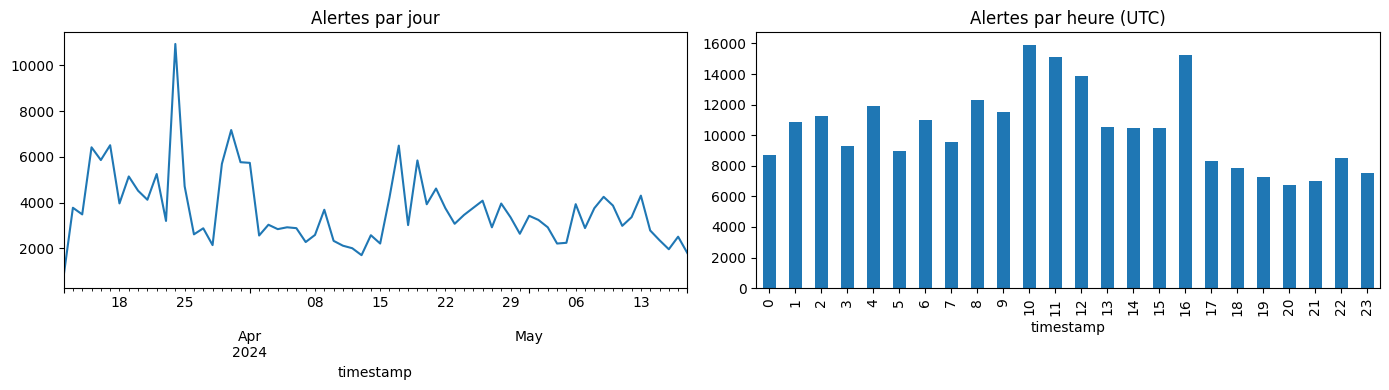

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
alerts.set_index("timestamp").resample("D").size().plot(ax=ax[0], title="Alertes par jour")
alerts["timestamp"].dt.hour.value_counts().sort_index().plot.bar(ax=ax[1], title="Alertes par heure (UTC)")
plt.tight_layout(); plt.show()

### 2.7 Que contiennent les « vraies » alertes ?
Sépare le bruit technique (`Generic Protocol Command Decode`) des autres alertes et affiche leurs sévérités et signatures.

In [9]:
real = alerts[alerts["category"] != "Generic Protocol Command Decode"]
print("Alertes hors bruit :", len(real), f"({len(real)/len(alerts):.1%} de l'échantillon)")
print("\nCatégorie x sévérité :\n", real.groupby(["category", "severity"]).size())
print("\nTop signatures hors bruit :\n", real["signature"].value_counts().head(15))

Alertes hors bruit : 198716 (79.4% de l'échantillon)

Catégorie x sévérité :
 category                                            severity
                                                    3                2
A Network Trojan was detected                       1              181
Attempted Administrator Privilege Gain              1             2339
Attempted Information Leak                          2            16778
Attempted User Privilege Gain                       1              139
Detection of a Network Scan                         3             6202
Information Leak                                    2              866
Misc Attack                                         2            12082
Misc activity                                       3           121054
Not Suspicious Traffic                              3            31203
Potential Corporate Privacy Violation               1              993
Potentially Bad Traffic                             2             3267
Web Appli

## Phase 3 — Data Preparation (préparation des données)

### 3.1 Construction des labels (faibles)
Construit les deux labels au niveau de l'alerte :
- `label_v1` : sévérité ≤ 2 ou scan réseau (résultat principal) ;
- `label_v2` : `label_v1` **ou** signature contenant l'un des mots-clés de `SENSITIVE`.

`LABEL_VERSION` (cellule 0.2) choisit celui qui sert à entraîner les modèles. Les deux restent disponibles pour la comparaison de la section 5.8.



In [10]:
pat_sensitive = "|".join(re.escape(k) for k in SENSITIVE)

alerts["label_v1"] = ((alerts["severity"] <= 2) |
                      (alerts["category"] == "Detection of a Network Scan")).astype(int)
alerts["label_v2"] = (alerts["label_v1"].astype(bool) |
                      alerts["signature"].str.contains(pat_sensitive, case=False, na=False)).astype(int)

print("Part de positifs (%) :")
print((alerts[["label_v1", "label_v2"]].mean() * 100).round(1).to_string())

Part de positifs (%) :
label_v1    18.6
label_v2    25.7


### 3.2 Jointure alertes ↔ flux (sens client → serveur)


In [11]:
lab = alerts.groupby("flow_id", as_index=False).agg(
    label_v1=("label_v1", "max"), label_v2=("label_v2", "max"),
    app_proto=("app_proto", "first"), ts=("timestamp", "first"))

flow_cols = ["flow_id", "src_ip", "dest_ip", "src_port", "dest_port", "proto",
             "pkts_toserver", "pkts_toclient", "bytes_toserver", "bytes_toclient",
             "age", "state", "reason"]
fl = flows[flow_cols].drop_duplicates("flow_id")

df = lab.merge(fl, on="flow_id", how="left")
print("Alertes avec flux associé :", round(df["src_ip"].notna().mean(), 3))
df = df.dropna(subset=["src_ip"]).copy()    # flux coupés en fin d'extraction

df["label"] = df["label_v1"] if LABEL_VERSION == "v1" else df["label_v2"]

sig = alerts.sort_values("severity").groupby("flow_id")["signature"].first()
df["sig"] = df["flow_id"].map(sig)          # analyse uniquement, jamais une feature

print("Lignes :", len(df), "| IP sources :", df["src_ip"].nunique(), "| IP dest :", df["dest_ip"].nunique())
print("Label retenu :", LABEL_VERSION, "| part de positifs :", round(df["label"].mean(), 3))
print(df["dest_port"].value_counts().head(8))

Alertes avec flux associé : 1.0
Lignes : 143807 | IP sources : 15663 | IP dest : 10
Label retenu : v1 | part de positifs : 0.218
dest_port
80.0       92960
443.0      26081
22.0       16270
3306.0      2027
10000.0      610
5201.0        17
Name: count, dtype: int64


### 3.3 Création des features
Features **sans fuite** : uniquement des informations connues au moment de l'alerte.


In [12]:
df = df.dropna(subset=["ts"]).sort_values("ts").reset_index(drop=True)
df["hour"] = df["ts"].dt.hour
df["dow"] = df["ts"].dt.dayofweek
df["bytes_ratio"] = df["bytes_toserver"] / (df["bytes_toclient"] + 1)
df["pkts_total"] = df["pkts_toserver"] + df["pkts_toclient"]
df["ip_prev_alerts"] = df.groupby("src_ip").cumcount()
df["ip_gap_s"] = df.groupby("src_ip")["ts"].diff().dt.total_seconds().fillna(-1)
df[["ts", "src_ip", "label", "bytes_ratio", "pkts_total", "ip_prev_alerts", "ip_gap_s"]].head()

,ts,src_ip,label,bytes_ratio,pkts_total,ip_prev_alerts,ip_gap_s
0,2024-03-12 07:56:39.951078+00:00,192.168.33.9,0,0.033532,434.0,0,-1.000000
1,2024-03-12 08:09:21.164148+00:00,10.10.12.2,0,1.068249,144.0,0,-1.000000
2,2024-03-12 08:13:50.472561+00:00,192.168.33.9,0,0.030764,138.0,1,1030.521483
3,2024-03-12 08:13:51.045820+00:00,192.168.33.9,0,0.043622,153.0,2,0.573259
4,2024-03-12 08:40:10.470488+00:00,192.168.33.9,0,0.999261,17.0,3,1579.424668


### 3.4 Profil d'hôte à partir des agrégats (IP, heure)
Utilise les agrégats `hosthour` calculés sur **tout** le trafic. Pour chaque alerte, on ne regarde que le **passé strict** de l'IP cliente (heures antérieures à celle de l'alerte) :
- `hist_flows`, `hist_alerted`, `hist_alert_rate` : historique cumulé de l'IP (nombre de flux, part de flux ayant déclenché une alerte) ;
- `is_new_host` : première apparition de l'IP ;
- `prev1h_flows`, `prev1h_alerted`, `prev1h_ports` : activité de l'IP pendant l'heure précédente (`prev1h_ports` élevé = balayage de ports).

L'heure courante est exclue volontairement : elle contient le flux de l'alerte elle-même (fuite de données).

In [13]:
hh = pd.concat([pd.read_parquet(f"{OUT}/{f}") for f in sorted(os.listdir(OUT)) if f.startswith("hosthour")],
               ignore_index=True)
hh["hour"] = pd.to_datetime(hh["hour"], format="%Y-%m-%dT%H", utc=True).astype("datetime64[ns, UTC]")
hh = hh.groupby(["src_ip", "hour"], as_index=False).sum()
hh = hh.sort_values(["src_ip", "hour"]).reset_index(drop=True)
g = hh.groupby("src_ip")
hh["cum_flows"] = g["n_flows"].cumsum()
hh["cum_alerted"] = g["n_alerted"].cumsum()
hh = hh.sort_values("hour").reset_index(drop=True)

df["hour_bucket"] = df["ts"].dt.floor("h").astype("datetime64[ns, UTC]")
df = df.sort_values("hour_bucket", kind="mergesort").reset_index(drop=True)
keys = df[["flow_id", "src_ip", "hour_bucket"]]

hist = pd.merge_asof(keys, hh[["src_ip", "hour", "cum_flows", "cum_alerted"]],
                     left_on="hour_bucket", right_on="hour", by="src_ip",
                     direction="backward", allow_exact_matches=False)
prev = pd.merge_asof(keys, hh[["src_ip", "hour", "n_flows", "n_alerted", "n_ports"]],
                     left_on="hour_bucket", right_on="hour", by="src_ip",
                     direction="backward", allow_exact_matches=False, tolerance=pd.Timedelta(hours=1))

df["hist_flows"] = hist["cum_flows"].fillna(0).values
df["hist_alerted"] = hist["cum_alerted"].fillna(0).values
df["hist_alert_rate"] = df["hist_alerted"] / (df["hist_flows"] + 1)
df["is_new_host"] = (df["hist_flows"] == 0).astype(int)
df["prev1h_flows"] = prev["n_flows"].fillna(0).values
df["prev1h_alerted"] = prev["n_alerted"].fillna(0).values
df["prev1h_ports"] = prev["n_ports"].fillna(0).values

host_feats = ["hist_flows", "hist_alerted", "hist_alert_rate", "is_new_host",
              "prev1h_flows", "prev1h_alerted", "prev1h_ports"]
df = df.sort_values("ts", kind="mergesort").reset_index(drop=True)   # retour à l'ordre chronologique
print("Couples (IP, heure) :", len(hh), "| nouvelles IP parmi les alertes :", round(df["is_new_host"].mean(), 3))
df[["ts", "src_ip", "label"] + host_feats].head()

Couples (IP, heure) : 1150798 | nouvelles IP parmi les alertes : 0.127


,ts,src_ip,label,hist_flows,hist_alerted,hist_alert_rate,is_new_host,prev1h_flows,prev1h_alerted,prev1h_ports
0,2024-03-12 07:56:39.951078+00:00,192.168.33.9,0,0.0,0.0,0.00,1,0.0,0.0,0.0
1,2024-03-12 08:09:21.164148+00:00,10.10.12.2,0,0.0,0.0,0.00,1,0.0,0.0,0.0
2,2024-03-12 08:13:50.472561+00:00,192.168.33.9,0,3.0,1.0,0.25,0,3.0,1.0,2.0
3,2024-03-12 08:13:51.045820+00:00,192.168.33.9,0,3.0,1.0,0.25,0,3.0,1.0,2.0
4,2024-03-12 08:40:10.470488+00:00,192.168.33.9,0,3.0,1.0,0.25,0,3.0,1.0,2.0


### 3.5 Matrice de features et découpage temporel


In [14]:
cat = ["proto", "app_proto", "state", "reason"]
num = ["dest_port", "pkts_toserver", "pkts_toclient", "bytes_toserver", "bytes_toclient",
       "age", "bytes_ratio", "pkts_total", "hour", "dow", "ip_prev_alerts", "ip_gap_s"] + host_feats

X = pd.get_dummies(df[num + cat], columns=cat, dummy_na=True).astype("float32").fillna(0)
X.columns = [re.sub(r"[^0-9a-zA-Z_]", "_", c) for c in X.columns]   # noms compatibles LightGBM
y = df["label"]

leak = ("signature", "category", "severity", "label")
assert not any(c.startswith(leak) for c in X.columns), "Fuite de données détectée dans X"

cut = int(len(df) * 0.8)
Xtr, Xte, ytr, yte = X.iloc[:cut], X.iloc[cut:], y.iloc[:cut], y.iloc[cut:]
print("Train :", Xtr.shape, "| Test :", Xte.shape)
print("Période train :", df["ts"].iloc[0], "→", df["ts"].iloc[cut - 1])
print("Période test  :", df["ts"].iloc[cut], "→", df["ts"].iloc[-1])
print("Positifs train / test :", round(ytr.mean(), 3), "/", round(yte.mean(), 3))

Train : (115045, 37) | Test : (28762, 37)
Période train : 2024-03-12 07:56:39.951078+00:00 → 2024-05-03 04:57:06.329423+00:00
Période test  : 2024-05-03 04:57:06.329441+00:00 → 2024-05-18 17:17:38.863796+00:00
Positifs train / test : 0.211 / 0.247


### 3.6 Contrôles de cohérence du jeu de données


In [15]:
print("Taux de positifs et nombre d'alertes par jour :")
print(df.groupby(df["ts"].dt.date)["label"].agg(taux="mean", n="size").round(3))

pos = df[df["label"] == 1]
print("\nPart des 5 IP sources les plus actives parmi les positifs (%) :")
print((pos["src_ip"].value_counts(normalize=True).head(5) * 100).round(1))

print("\nSignatures qui portent le label (%) :")
print((pos["sig"].value_counts(normalize=True).head(8) * 100).round(1))

tr_ips = set(df["src_ip"].iloc[:cut])
te_ = df.iloc[cut:]
print("\nAlertes du test dont l'IP est déjà dans le train :", round(te_["src_ip"].isin(tr_ips).mean(), 3))
assert len(df) == len(X) == len(y), "df et X désalignés : relancer depuis la cellule 3.2"

Taux de positifs et nombre d'alertes par jour :
             taux     n
ts                     
2024-03-12  0.393   410
2024-03-13  0.258  2259
2024-03-14  0.227  1939
2024-03-15  0.088  5158
2024-03-16  0.127  3690
...           ...   ...
2024-05-14  0.319  1550
2024-05-15  0.269  1266
2024-05-16  0.324  1126
2024-05-17  0.393  1495
2024-05-18  0.375   934

[68 rows x 2 columns]

Part des 5 IP sources les plus actives parmi les positifs (%) :
src_ip
192.168.33.9       14.2
172.232.237.101     5.2
43.254.59.190       3.3
194.163.182.221     2.5
146.19.24.28        1.3
Name: proportion, dtype: float64

Signatures qui portent le label (%) :
sig
ET SCAN WordPress Scanner Performing Multiple Requests to Windows Live Writer XML    17.7
GPL WEB_SERVER 403 Forbidden                                                         14.5
ET DROP Dshield Block Listed Source group 1                                          11.6
ET SCAN Suspicious inbound to mySQL port 3306                                  

### 3.7 Sauvegarde du jeu de données


In [16]:
df.to_parquet(ML_PATH, index=False)
print("Sauvegardé :", ML_PATH, f"({os.path.getsize(ML_PATH)/1e6:.1f} Mo)")

Sauvegardé : /kaggle/working/ml_dataset.parquet (8.4 Mo)


## Phase 4 — Modeling (modélisation)

### 4.1 MLflow et fonction d'évaluation
- **précision, rappel, F1** (au seuil 0,5),
- **AUC-PR** 
- **ROC-AUC**.

L'accuracy n'est volontairement pas utilisée.

In [17]:
import mlflow
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             roc_auc_score, confusion_matrix, precision_recall_curve,
                             classification_report, ConfusionMatrixDisplay)

mlflow.set_tracking_uri(f"sqlite:///{WORK}/mlflow.db")
if mlflow.get_experiment_by_name("suricata-detection") is None:
    mlflow.create_experiment("suricata-detection", artifact_location=f"{WORK}/mlartifacts")
mlflow.set_experiment("suricata-detection")

def evaluate(y_true, score, pred):
    return {"precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "auc_pr": average_precision_score(y_true, score),
            "roc_auc": roc_auc_score(y_true, score)}

results, test_scores = [], {}
print("MLflow prêt")

2026/11/17 11:02:44 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/17 11:02:44 INFO mlflow.store.db.utils: Updating database tables


MLflow prêt


### 4.2 Baseline + modèles supervisés + modèle non supervisé


In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMClassifier

models = {
    "baseline": DummyClassifier(strategy="prior"),
    "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "random_forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=SEED),
    "lightgbm": LGBMClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, verbose=-1),
}

for name, m in models.items():
    with mlflow.start_run(run_name=name):
        m.fit(Xtr, ytr)
        score = m.predict_proba(Xte)[:, 1]
        r = evaluate(yte, score, (score >= 0.5).astype(int))
        mlflow.log_params({"model": name, "split": "temporal_80_20", "n_features": Xtr.shape[1]})
        mlflow.log_metrics(r)
        results.append({"model": name, **r}); test_scores[name] = score

# Isolation Forest (non supervisé : n'utilise pas ytr)
with mlflow.start_run(run_name="isolation_forest"):
    contam = float(min(max(ytr.mean(), 0.01), 0.5))
    iso = IsolationForest(n_estimators=200, contamination=contam, random_state=SEED, n_jobs=-1).fit(Xtr)
    score = -iso.decision_function(Xte)               # plus haut = plus anormal
    r = evaluate(yte, score, (iso.predict(Xte) == -1).astype(int))
    mlflow.log_params({"model": "isolation_forest", "contamination": contam})
    mlflow.log_metrics(r)
    results.append({"model": "isolation_forest", **r}); test_scores["isolation_forest"] = score

results_df = pd.DataFrame(results).round(3).sort_values("auc_pr", ascending=False)
print("Prévalence du test (= AUC-PR d'un modèle sans information) :", round(yte.mean(), 3))
print(results_df.to_string(index=False))

Prévalence du test (= AUC-PR d'un modèle sans information) : 0.247
           model  precision  recall    f1  auc_pr  roc_auc
   random_forest      0.954   0.861 0.905   0.979    0.992
        lightgbm      0.915   0.921 0.918   0.977    0.991
          logreg      0.500   0.730 0.593   0.695    0.845
        baseline      0.000   0.000 0.000   0.247    0.500
isolation_forest      0.174   0.250 0.205   0.220    0.488


### 4.3 Réglage des hyperparamètres (Optuna)


In [19]:
import optuna
from sklearn.model_selection import TimeSeriesSplit
optuna.logging.set_verbosity(optuna.logging.WARNING)

tscv = TimeSeriesSplit(n_splits=3)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 8, 48),
        "min_child_samples": trial.suggest_int("min_child_samples", 30, 200),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 20.0, log=True),
        "subsample_freq": 1,
    }
    scores = []
    for tr, va in tscv.split(Xtr):
        m = LGBMClassifier(**params, class_weight="balanced", random_state=SEED, verbose=-1)
        m.fit(Xtr.iloc[tr], ytr.iloc[tr])
        scores.append(average_precision_score(ytr.iloc[va], m.predict_proba(Xtr.iloc[va])[:, 1]))
    return float(np.mean(scores))

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS)
optuna_params = dict(study.best_params, subsample_freq=1)
print("Meilleurs paramètres Optuna :", optuna_params)
print("AUC-PR validation temporelle (moyenne) :", round(study.best_value, 3))

Meilleurs paramètres Optuna : {'n_estimators': 303, 'learning_rate': 0.08254420044461724, 'num_leaves': 42, 'min_child_samples': 50, 'subsample': 0.6728678349964421, 'colsample_bytree': 0.6713152343532499, 'reg_lambda': 0.3708293819885645, 'subsample_freq': 1}
AUC-PR validation temporelle (moyenne) : 0.964


### 4.4 Choix de la configuration finale


In [20]:
def ap(y_true, s):
    """AUC-PR (average precision) ; None si une seule classe est présente."""
    y_true = pd.Series(np.asarray(y_true))
    return round(average_precision_score(y_true, s), 3) if y_true.nunique() == 2 else None

configs = {
    "défaut": dict(n_estimators=300),
    "optuna": optuna_params,
    "régularisé": dict(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=100,
                       reg_lambda=10, subsample=0.8, subsample_freq=1, colsample_bytree=0.8),
}
rows = []
for name, p in configs.items():
    cv = []
    for tr, va in TimeSeriesSplit(n_splits=4).split(Xtr):
        m = LGBMClassifier(**p, class_weight="balanced", random_state=SEED, verbose=-1).fit(Xtr.iloc[tr], ytr.iloc[tr])
        cv.append(average_precision_score(ytr.iloc[va], m.predict_proba(Xtr.iloc[va])[:, 1]))
    m = LGBMClassifier(**p, class_weight="balanced", random_state=SEED, verbose=-1).fit(Xtr, ytr)
    rows.append({"config": name, "cv_temporel": float(np.mean(cv)),
                 "train": ap(ytr, m.predict_proba(Xtr)[:, 1]), "test (info)": ap(yte, m.predict_proba(Xte)[:, 1])})
cmp_cfg = pd.DataFrame(rows)
print(cmp_cfg.round(3).to_string(index=False))

CHOSEN = cmp_cfg.loc[cmp_cfg["cv_temporel"].idxmax(), "config"]
best_params = configs[CHOSEN]
print("\nConfiguration retenue (meilleur AUC-PR en validation temporelle) :", CHOSEN)

def new_model(**kw):
    return LGBMClassifier(**best_params, class_weight="balanced", random_state=SEED, verbose=-1, **kw)

    config  cv_temporel  train  test (info)
    défaut        0.954  1.000        0.977
    optuna        0.953  1.000        0.979
régularisé        0.939  0.992        0.969

Configuration retenue (meilleur AUC-PR en validation temporelle) : défaut


### 4.5 Isolation Fores : quelles variables pour détecter l'anormal ?


In [21]:
from sklearn.ensemble import IsolationForest

size_cols = [c for c in Xtr.columns if c.startswith(("pkts", "bytes"))]
variants = {
    "toutes les variables": (Xtr, Xte),
    "profil d'hôte seul": (Xtr[host_feats], Xte[host_feats]),
    "profil d'hôte (log1p)": (np.log1p(Xtr[host_feats]), np.log1p(Xte[host_feats])),
    "taille du flux seule": (Xtr[size_cols], Xte[size_cols]),
}
contam = float(min(max(ytr.mean(), 0.01), 0.5))
rows = []
for name, (A, B) in variants.items():
    iso_v = IsolationForest(n_estimators=200, contamination=contam, random_state=SEED, n_jobs=-1).fit(A)
    sc = -iso_v.decision_function(B)
    rows.append({"variante": name, "AUC-PR": ap(yte, sc), "ROC-AUC": round(roc_auc_score(yte, sc), 3)})
print("Prévalence du test (AUC-PR d'un modèle sans information) :", round(yte.mean(), 3))
print(pd.DataFrame(rows).to_string(index=False))

Prévalence du test (AUC-PR d'un modèle sans information) : 0.247
             variante  AUC-PR  ROC-AUC
 toutes les variables   0.220    0.488
   profil d'hôte seul   0.214    0.438
profil d'hôte (log1p)   0.206    0.418
 taille du flux seule   0.271    0.582


## Phase 5 — Evaluation (évaluation)



           model  precision  recall    f1  auc_pr  roc_auc
   random_forest      0.954   0.861 0.905   0.979    0.992
        lightgbm      0.915   0.921 0.918   0.977    0.991
          logreg      0.500   0.730 0.593   0.695    0.845
        baseline      0.000   0.000 0.000   0.247    0.500
isolation_forest      0.174   0.250 0.205   0.220    0.488


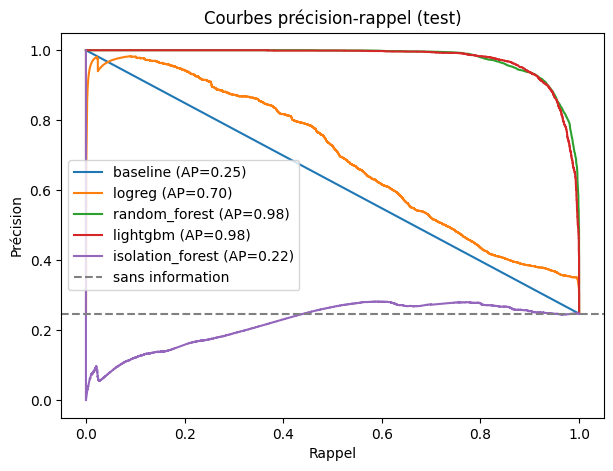

In [22]:
print(results_df.to_string(index=False))

plt.figure(figsize=(7, 5))
for name, sc in test_scores.items():
    p, r_, _ = precision_recall_curve(yte, sc)
    plt.plot(r_, p, label=f"{name} (AP={average_precision_score(yte, sc):.2f})")
plt.axhline(yte.mean(), color="grey", linestyle="--", label="sans information")
plt.xlabel("Rappel"); plt.ylabel("Précision"); plt.title("Courbes précision-rappel (test)")
plt.legend(); plt.show()

### 5.2 Modèle final, seuil de décision, matrice de confusion


Positifs dans les prédictions hors échantillon : 20467 | prévalence : 0.222
Seuil retenu : 0.5
{'precision': 0.915, 'recall': 0.921, 'f1': 0.918, 'auc_pr': 0.977, 'roc_auc': 0.991}
              precision    recall  f1-score   support

 non suspect       0.97      0.97      0.97     21651
     suspect       0.92      0.92      0.92      7111

    accuracy                           0.96     28762
   macro avg       0.94      0.95      0.95     28762
weighted avg       0.96      0.96      0.96     28762



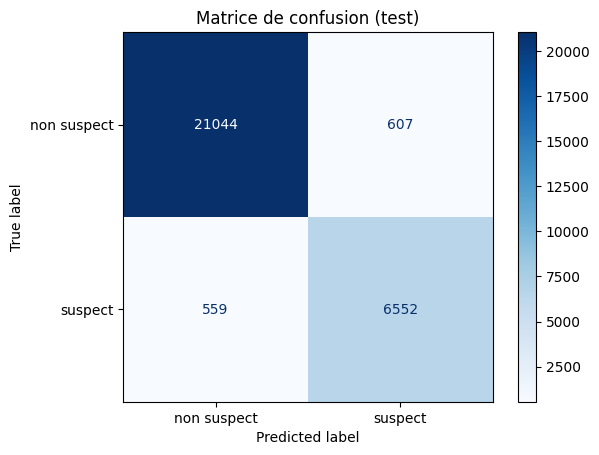


Prévalence du test (AUC-PR sans information) : 0.247
           model  precision  recall    f1  auc_pr  roc_auc
   random_forest      0.954   0.861 0.905   0.979    0.992
        lightgbm      0.915   0.921 0.918   0.977    0.991
  lightgbm_final      0.915   0.921 0.918   0.977    0.991
          logreg      0.500   0.730 0.593   0.695    0.845
        baseline      0.000   0.000 0.000   0.247    0.500
isolation_forest      0.174   0.250 0.205   0.220    0.488


In [23]:
best = new_model().fit(Xtr, ytr)

# Prédictions hors échantillon : chaque tranche est prédite par un modèle entraîné sur le passé
oof_idx, oof_p = [], []
for tr, va in TimeSeriesSplit(n_splits=4).split(Xtr):
    m = new_model().fit(Xtr.iloc[tr], ytr.iloc[tr])
    oof_idx.append(va); oof_p.append(m.predict_proba(Xtr.iloc[va])[:, 1])
oof_idx, oof_p = np.concatenate(oof_idx), np.concatenate(oof_p)
y_oof = ytr.iloc[oof_idx]
print("Positifs dans les prédictions hors échantillon :", int(y_oof.sum()), "| prévalence :", round(y_oof.mean(), 3))

prec_o, rec_o, thr_o = precision_recall_curve(y_oof, oof_p)
ok = np.where(rec_o[:-1] >= RECALL_TARGET)[0]
if len(ok):
    THR = float(thr_o[ok[-1]])                       # seuil le plus haut qui garde le rappel visé
else:
    f1_o = 2 * prec_o * rec_o / (prec_o + rec_o + 1e-9)
    THR = float(thr_o[np.argmax(f1_o[:-1])])         # repli : meilleur F1
print("Seuil retenu :", round(THR, 3))

pt = best.predict_proba(Xte)[:, 1]
pred = (pt >= THR).astype(int)
final = evaluate(yte, pt, pred)
print({k: round(float(v), 3) for k, v in final.items()})
print(classification_report(yte, pred, target_names=["non suspect", "suspect"], zero_division=0))

ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=["non suspect", "suspect"]).plot(cmap="Blues")
plt.title("Matrice de confusion (test)"); plt.show()

with mlflow.start_run(run_name="lightgbm_final"):
    mlflow.log_params({**best_params, "config": CHOSEN, "threshold": THR, "label_version": LABEL_VERSION})
    mlflow.log_metrics(final)

results.append({"model": "lightgbm_final", **final}); test_scores["lightgbm_final"] = pt
results_df = pd.DataFrame(results).round(3).sort_values("auc_pr", ascending=False)
print("\nPrévalence du test (AUC-PR sans information) :", round(yte.mean(), 3))
print(results_df.to_string(index=False))

### 5.3 Explicabilité (SHAP)


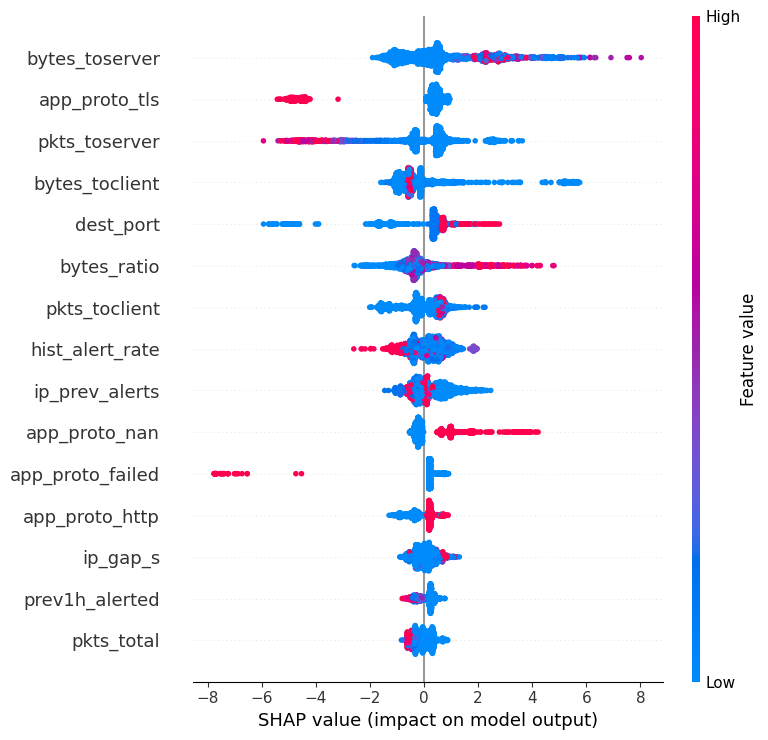

In [24]:
import shap
explainer = shap.TreeExplainer(best)
sample = Xte.sample(min(2000, len(Xte)), random_state=SEED)
sv = explainer.shap_values(sample)
if isinstance(sv, list):
    sv = sv[1]
elif getattr(sv, "ndim", 2) == 3:
    sv = sv[:, :, 1]
shap.summary_plot(sv, sample, max_display=15)

### 5.4 Diagnostic de santé du modèle (surapprentissage, fuite, dépendances)


In [25]:
assert len(df) == len(X) == len(y), "df et X désalignés : relancer depuis la cellule 3.2"
sc_tr = best.predict_proba(Xtr)[:, 1]

print("=== 1. Train / hors échantillon (validation temporelle) / test ===")
print(f"train        prévalence={ytr.mean():.3f} | AUC-PR={ap(ytr, sc_tr)}")
print(f"hors échant. prévalence={y_oof.mean():.3f} | AUC-PR={ap(y_oof, oof_p)}")
print(f"test         prévalence={yte.mean():.3f} | AUC-PR={ap(yte, pt)} | rappel={recall_score(yte, pred):.3f} | F1={f1_score(yte, pred):.3f}")

print("\n=== 2. Labels mélangés, 5 graines (ROC-AUC attendu ≈ 0,5) ===")
res = []
for s in range(5):
    ysh = pd.Series(np.random.RandomState(s).permutation(ytr.values), index=ytr.index)
    p0 = new_model().fit(Xtr, ysh).predict_proba(Xte)[:, 1]
    res.append((ap(yte, p0), roc_auc_score(yte, p0)))
r = pd.DataFrame(res, columns=["AUC-PR", "ROC-AUC"])
print(r.round(3).to_string(index=False))
print("moyenne :", r.mean().round(3).to_dict(), "| prévalence test :", round(yte.mean(), 3))

print("\n=== 3. Dépendance à quelques variables ===")
imp = pd.Series(best.booster_.feature_importance(importance_type="gain"), index=Xtr.columns).sort_values(ascending=False)
print((imp.head(5) / imp.sum() * 100).round(1).to_string())
for f in imp.index[:3]:
    m1 = LGBMClassifier(n_estimators=200, class_weight="balanced", random_state=SEED, verbose=-1).fit(Xtr[[f]], ytr)
    print(f"  '{f}' seule -> AUC-PR test = {ap(yte, m1.predict_proba(Xte[[f]])[:, 1])}")

print("\n=== 4. Stabilité dans le temps (test en 4 tranches) ===")
for k, idx in enumerate(np.array_split(np.arange(len(Xte)), 4), 1):
    d0, d1 = df["ts"].iloc[cut + idx[0]].date(), df["ts"].iloc[cut + idx[-1]].date()
    print(f"  tranche {k} ({d0} -> {d1}) n={len(idx)} positifs={int(yte.iloc[idx].sum())} prévalence={yte.iloc[idx].mean():.3f} AUC-PR={ap(yte.iloc[idx], pt[idx])}")

print("\n=== 5. IP déjà vues dans le train ou nouvelles ===")
seen = df["src_ip"].iloc[cut:].isin(set(df["src_ip"].iloc[:cut])).values
for lab_, mask in [("IP déjà vue", seen), ("IP nouvelle", ~seen)]:
    if mask.sum() > 0:
        print(f"  {lab_}: n={mask.sum()} prévalence={yte.values[mask].mean():.3f} AUC-PR={ap(yte.values[mask], pt[mask])}")

print("\n=== 6. Courbe d'apprentissage (données les plus récentes du train) ===")
for frac in [0.25, 0.5, 0.75, 1.0]:
    n = int(len(Xtr) * frac)
    m = new_model().fit(Xtr.iloc[-n:], ytr.iloc[-n:])
    print(f"  {int(frac*100):3d}% du train (n={n}) -> AUC-PR train={ap(ytr.iloc[-n:], m.predict_proba(Xtr.iloc[-n:])[:, 1])} | test={ap(yte, m.predict_proba(Xte)[:, 1])}")

print("\n=== 7. Sans les variables de taille du flux ===")
m_ns = new_model().fit(Xtr.drop(columns=size_cols), ytr)
print("AUC-PR test sans variables de taille :", ap(yte, m_ns.predict_proba(Xte.drop(columns=size_cols))[:, 1]), "| avec :", ap(yte, pt))

=== 1. Train / hors échantillon (validation temporelle) / test ===
train        prévalence=0.211 | AUC-PR=1.0
hors échant. prévalence=0.222 | AUC-PR=0.955
test         prévalence=0.247 | AUC-PR=0.977 | rappel=0.921 | F1=0.918

=== 2. Labels mélangés, 5 graines (ROC-AUC attendu ≈ 0,5) ===
 AUC-PR  ROC-AUC
  0.245    0.510
  0.269    0.527
  0.287    0.571
  0.286    0.549
  0.286    0.570
moyenne : {'AUC-PR': 0.275, 'ROC-AUC': 0.546} | prévalence test : 0.247

=== 3. Dépendance à quelques variables ===
bytes_ratio         20.8
bytes_toserver      16.3
hist_alert_rate      9.9
app_proto_tls        6.6
app_proto_failed     5.7
  'bytes_ratio' seule -> AUC-PR test = 0.768
  'bytes_toserver' seule -> AUC-PR test = 0.744
  'hist_alert_rate' seule -> AUC-PR test = 0.425

=== 4. Stabilité dans le temps (test en 4 tranches) ===
  tranche 1 (2024-05-03 -> 2024-05-07) n=7191 positifs=1540 prévalence=0.214 AUC-PR=0.974
  tranche 2 (2024-05-07 -> 2024-05-10) n=7191 positifs=1434 prévalence=0.199 AU

### 5.5 Intervalles de confiance (bootstrap par IP)


In [26]:
rng = np.random.RandomState(SEED)
te_ = df.iloc[cut:].reset_index(drop=True)
groups_ip = te_.groupby("src_ip").indices            # IP -> positions dans le test
ips = np.array(list(groups_ip.keys()))
yv = yte.values

def metrics(idx):
    y_, s_, p_ = yv[idx], pt[idx], pred[idx]
    return (average_precision_score(y_, s_), precision_score(y_, p_, zero_division=0), recall_score(y_, p_, zero_division=0))

boot = []
for _ in range(200):
    pick = rng.choice(len(ips), size=len(ips), replace=True)
    idx = np.concatenate([groups_ip[ips[i]] for i in pick])
    if yv[idx].min() != yv[idx].max():
        boot.append(metrics(idx))
boot = np.array(boot)
base = metrics(np.arange(len(yv)))

ci = {}
print("IP distinctes dans le test :", len(ips), "| alertes :", len(yv))
for k, name in enumerate(["auc_pr", "precision", "rappel"]):
    lo, hi = np.percentile(boot[:, k], [2.5, 97.5])
    ci[name] = (float(base[k]), float(lo), float(hi))
    print(f"{name:10s} {base[k]:.3f}  IC 95 % (bootstrap par IP) : [{lo:.3f} ; {hi:.3f}]")

IP distinctes dans le test : 5253 | alertes : 28762
auc_pr     0.977  IC 95 % (bootstrap par IP) : [0.957 ; 0.989]
precision  0.915  IC 95 % (bootstrap par IP) : [0.869 ; 0.960]
rappel     0.921  IC 95 % (bootstrap par IP) : [0.871 ; 0.959]


### 5.6 Analyse par famille de signatures


In [27]:
# --- 5.6a : rappel par famille et faux positifs ---
te_f = df.iloc[cut:].reset_index(drop=True).copy()
te_f["pred"] = pred
te_f["y"] = yte.values
nt = np.empty(len(te_f), dtype=int)
for k, ix in enumerate(np.array_split(np.arange(len(te_f)), 4), 1):
    nt[ix] = k
te_f["tranche"] = nt

fam = (te_f[te_f["y"] == 1].groupby("sig")
       .agg(rappel=("pred", "mean"), alertes=("pred", "size"), ip_distinctes=("src_ip", "nunique"))
       .sort_values("alertes", ascending=False).head(10).round(2))
print("Rappel par famille de signatures positives (test) :")
print(fam.to_string())

fp = te_f[(te_f["pred"] == 1) & (te_f["y"] == 0)]["sig"].value_counts().head(5)
print("\nPrincipales familles de faux positifs :")
print(fp.to_string())

Rappel par famille de signatures positives (test) :
                                                                                   rappel  alertes  ip_distinctes
sig                                                                                                              
ET SCAN WordPress Scanner Performing Multiple Requests to Windows Live Writer XML    0.99     1708            127
ET DROP Dshield Block Listed Source group 1                                          1.00      952            541
GPL WEB_SERVER 403 Forbidden                                                         0.90      771            148
ET SCAN Suspicious inbound to mySQL port 3306                                        1.00      418            197
ET WEB_SERVER PHP tags in HTTP POST                                                  0.55      330             11
ET EXPLOIT Possible MovableTypePoC RCE Inbound (CVE-2021-20837)                      1.00      300              2
ET SCAN SFTP/FTP Password Exposure v

In [28]:
# --- 5.6b : rappel par tranche du test pour les 5 premières familles ---
top5 = fam.index[:5]
piv = (te_f[(te_f["y"] == 1) & te_f["sig"].isin(top5)]
       .pivot_table(index="sig", columns="tranche", values="pred", aggfunc="mean").round(2))
print("Rappel par tranche (familles positives principales) :")
print(piv.to_string())

neg_top = te_f[te_f["y"] == 0]["sig"].value_counts().head(3).index
piv_fp = (te_f[(te_f["y"] == 0) & te_f["sig"].isin(neg_top)]
          .pivot_table(index="sig", columns="tranche", values="pred", aggfunc="mean").round(2))
print("\nPart prédite positive (faux positifs) par tranche, familles négatives principales :")
print(piv_fp.to_string())

Rappel par tranche (familles positives principales) :
tranche                                                                               1     2     3     4
sig                                                                                                      
ET DROP Dshield Block Listed Source group 1                                        0.99  1.00  1.00  1.00
ET SCAN Suspicious inbound to mySQL port 3306                                      1.00  1.00  1.00  1.00
ET SCAN WordPress Scanner Performing Multiple Requests to Windows Live Writer XML  1.00  0.97  1.00  1.00
ET WEB_SERVER PHP tags in HTTP POST                                                0.36  0.78  0.13  0.78
GPL WEB_SERVER 403 Forbidden                                                       0.85  0.66  0.86  0.96

Part prédite positive (faux positifs) par tranche, familles négatives principales :
tranche                                                       1     2     3     4
sig                                  

In [29]:
# --- 5.6c : dérive de la composition des positifs, train vs test ---
split_ = np.where(np.arange(len(df)) < cut, "train", "test")
mask_ = (df["label"] == 1).values
tab = pd.crosstab(df.loc[mask_, "sig"].values, split_[mask_])
for col in ["train", "test"]:
    if col not in tab.columns:
        tab[col] = 0
print("Positifs par signature (train vs test) :")
print(tab.sort_values("train", ascending=False).head(12).to_string())

Positifs par signature (train vs test) :
col_0                                                                              test  train
row_0                                                                                         
ET SCAN WordPress Scanner Performing Multiple Requests to Windows Live Writer XML  1708   3823
GPL WEB_SERVER 403 Forbidden                                                        771   3784
ET DROP Dshield Block Listed Source group 1                                         952   2669
ET SCAN Suspicious inbound to mySQL port 3306                                       418   1356
ET SCAN SFTP/FTP Password Exposure via sftp-config.json                             291   1153
ET EXPLOIT Possible MovableTypePoC RCE Inbound (CVE-2021-20837)                     300    908
ET DROP Spamhaus DROP Listed Traffic Inbound group 7                                181    659
ET INFO Request for Visual Studio Code sftp.json - Possible Information Leak        163    637
ET WEB_SE

In [30]:
# --- 5.6d : combien d'IP distinctes derrière chaque famille ? ---
rows = []
trd, ted = df.iloc[:cut], df.iloc[cut:]
for s in fam.index[:5]:
    a = trd.loc[(trd["sig"] == s) & (trd["label"] == 1), "src_ip"]
    b = ted.loc[(ted["sig"] == s) & (ted["label"] == 1), "src_ip"]
    rows.append({"signature": s[:55], "alertes train": len(a), "IP train": a.nunique(),
                 "alertes test": len(b), "IP test": b.nunique(), "IP communes": len(set(a) & set(b)),
                 "part top-3 IP (train)": round(a.value_counts(normalize=True).head(3).sum(), 2) if len(a) else None})
print(pd.DataFrame(rows).to_string(index=False))

                                              signature  alertes train  IP train  alertes test  IP test  IP communes  part top-3 IP (train)
ET SCAN WordPress Scanner Performing Multiple Requests            3823       343          1708      127           25                   0.55
            ET DROP Dshield Block Listed Source group 1           2669       932           952      541          423                   0.06
                           GPL WEB_SERVER 403 Forbidden           3784       265           771      148           20                   0.55
          ET SCAN Suspicious inbound to mySQL port 3306           1356       587           418      197           67                   0.04
                    ET WEB_SERVER PHP tags in HTTP POST            434        75           330       11            5                   0.45


### 5.7 Ablation par groupes de variables


In [31]:
groups = {
    "taille du flux": size_cols,
    "historique IP (échantillon)": [c for c in ["ip_prev_alerts", "ip_gap_s"] if c in Xtr.columns],
    "profil d'hôte (agrégats)": [c for c in host_feats if c in Xtr.columns],
    "temps": [c for c in ["hour", "dow"] if c in Xtr.columns],
    "protocole / port": [c for c in Xtr.columns if c.startswith(("proto_", "app_proto_", "state_", "reason_")) or c == "dest_port"],
}
ref = ap(yte, new_model().fit(Xtr, ytr).predict_proba(Xte)[:, 1])
rows = [{"groupe": "(toutes les variables)", "sans ce groupe": ref, "ce groupe seul": None}]
for name, cols in groups.items():
    rest = [c for c in Xtr.columns if c not in cols]
    a_wo = ap(yte, new_model().fit(Xtr[rest], ytr).predict_proba(Xte[rest])[:, 1])
    a_only = ap(yte, new_model().fit(Xtr[cols], ytr).predict_proba(Xte[cols])[:, 1])
    rows.append({"groupe": name, "sans ce groupe": a_wo, "ce groupe seul": a_only})
print("AUC-PR test | prévalence =", round(yte.mean(), 3))
print(pd.DataFrame(rows).to_string(index=False))

AUC-PR test | prévalence = 0.247
                     groupe  sans ce groupe  ce groupe seul
     (toutes les variables)           0.977             NaN
             taille du flux           0.889           0.945
historique IP (échantillon)           0.975           0.389
   profil d'hôte (agrégats)           0.974           0.515
                      temps           0.978           0.254
           protocole / port           0.967           0.619


### 5.8 Comparaison label v1 / label v2


In [32]:
rows, store = [], {}
for lab_name in ["label_v1", "label_v2"]:
    yy = df[lab_name]
    a, b = yy.iloc[:cut], yy.iloc[cut:]
    s_ = new_model().fit(Xtr, a).predict_proba(Xte)[:, 1]
    p_ = (s_ >= 0.5).astype(int)
    store[lab_name] = (b, s_, p_)
    ap_ = ap(b, s_)
    rows.append({"label": lab_name, "prévalence train": round(a.mean(), 3), "prévalence test": round(b.mean(), 3),
                 "AUC-PR": ap_, "x prévalence": round(ap_ / b.mean(), 1),
                 "précision": round(precision_score(b, p_, zero_division=0), 3), "rappel": round(recall_score(b, p_), 3)})
print(pd.DataFrame(rows).to_string(index=False))

# Décomposition du label v2
b2, s2, p2 = store["label_v2"]
te2 = df.iloc[cut:].reset_index(drop=True).copy()
te2["pred_v2"] = p2
te2["y1"] = df["label_v1"].iloc[cut:].values
te2["y2"] = b2.values
te2["v2_only"] = ((te2["y2"] == 1) & (te2["y1"] == 0)).astype(int)

print("\nPositifs v2 (test) :", int(te2["y2"].sum()), "| dont ajoutés par v2 :", int(te2["v2_only"].sum()))
print("Rappel sur les positifs d'origine (v1)  :", round(te2.loc[te2["y1"] == 1, "pred_v2"].mean(), 3))
print("Rappel sur les positifs ajoutés par v2  :", round(te2.loc[te2["v2_only"] == 1, "pred_v2"].mean(), 3))
print("Taux de faux positifs (négatifs v2)     :", round(te2.loc[te2["y2"] == 0, "pred_v2"].mean(), 3))
print("\nRappel par signature, label v2 (test) :")
print(te2[te2["y2"] == 1].groupby("sig")["pred_v2"].agg(rappel="mean", n="size")
      .sort_values("n", ascending=False).head(10).round(2))

   label  prévalence train  prévalence test  AUC-PR  x prévalence  précision  rappel
label_v1             0.211            0.247   0.977           4.0      0.915   0.921
label_v2             0.304            0.283   0.971           3.4      0.827   0.948

Positifs v2 (test) : 8135 | dont ajoutés par v2 : 1024
Rappel sur les positifs d'origine (v1)  : 0.958
Rappel sur les positifs ajoutés par v2  : 0.88
Taux de faux positifs (négatifs v2)     : 0.078

Rappel par signature, label v2 (test) :
                                                    rappel     n
sig                                                             
ET SCAN WordPress Scanner Performing Multiple R...    0.98  1708
ET INFO Request to Hidden Environment File - In...    0.88  1017
ET DROP Dshield Block Listed Source group 1           1.00   952
GPL WEB_SERVER 403 Forbidden                          0.92   771
ET SCAN Suspicious inbound to mySQL port 3306         1.00   418
ET WEB_SERVER PHP tags in HTTP POST               

### 5.9 Synthèse des résultats

In [33]:
summary = {
    "label_version": LABEL_VERSION,
    "max_lines": MAX_LINES,
    "periode": [str(df["ts"].min()), str(df["ts"].max())],
    "jours": int(df["ts"].dt.date.nunique()),
    "alertes_ml": int(len(df)),
    "ip_sources": int(df["src_ip"].nunique()),
    "n_features": int(Xtr.shape[1]),
    "prevalence_train": round(float(ytr.mean()), 3),
    "prevalence_test": round(float(yte.mean()), 3),
    "config_retenue": CHOSEN,
    "seuil": round(THR, 3),
    "metriques_test": {k: round(float(v), 3) for k, v in final.items()},
    "ic95_bootstrap_par_ip": {k: [round(v[1], 3), round(v[2], 3)] for k, v in ci.items()},
}
print(json.dumps(summary, indent=2, ensure_ascii=False))

with open(f"{WORK}/synthese_resultats.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
results_df.to_csv(f"{WORK}/resultats_modeles.csv", index=False)
with mlflow.start_run(run_name="synthese"):
    mlflow.log_artifact(f"{WORK}/synthese_resultats.json")
    mlflow.log_artifact(f"{WORK}/resultats_modeles.csv")

{
  "label_version": "v1",
  "max_lines": null,
  "periode": [
    "2024-03-12 07:56:39.951078+00:00",
    "2024-05-18 17:17:38.863796+00:00"
  ],
  "jours": 68,
  "alertes_ml": 143807,
  "ip_sources": 15663,
  "n_features": 37,
  "prevalence_train": 0.211,
  "prevalence_test": 0.247,
  "config_retenue": "défaut",
  "seuil": 0.5,
  "metriques_test": {
    "precision": 0.915,
    "recall": 0.921,
    "f1": 0.918,
    "auc_pr": 0.977,
    "roc_auc": 0.991
  },
  "ic95_bootstrap_par_ip": {
    "auc_pr": [
      0.957,
      0.989
    ],
    "precision": [
      0.869,
      0.96
    ],
    "rappel": [
      0.871,
      0.959
    ]
  }
}


In [34]:
proba_all = best.predict_proba(X)[:, 1]
anom_all = pd.Series(-iso.decision_function(X)).rank(pct=True).values
test_mask = np.arange(len(df)) >= cut

print("AUC-PR du score de risque (test) selon le poids de l'anomalie :")
for a in [0.0, 0.1, 0.3]:
    r_ = (1 - a) * proba_all + a * anom_all
    print(f"  alpha={a}: {ap(yte, r_[test_mask])}")

risk = 100 * ((1 - ALPHA) * proba_all + ALPHA * anom_all)
pred_df = df[["flow_id", "ts", "src_ip", "dest_ip", "dest_port", "proto", "app_proto", "label", "sig"]].copy()
pred_df["proba"] = proba_all
pred_df["anomaly"] = anom_all
pred_df["risk"] = risk.round(1)
pred_df["alert_pred"] = (proba_all >= THR).astype(int)
pred_df["split"] = np.where(test_mask, "test", "train")

host = pred_df.groupby("src_ip").agg(
    n_alerts=("flow_id", "count"), n_flagged=("alert_pred", "sum"),
    n_dest=("dest_ip", "nunique"), n_ports=("dest_port", "nunique"),
    risk_max=("risk", "max"), risk_mean=("risk", "mean"))
host["persistence"] = np.minimum(1, np.log10(host["n_alerts"] + 1) / 2)     # 100 alertes = 1
host["risk_host"] = (0.5 * host["risk_max"] + 0.3 * host["risk_mean"] + 20 * host["persistence"]).round(1)
host = host.sort_values("risk_host", ascending=False)

print("\nTop 10 hôtes :")
print(host.head(10).round(1).to_string())
print("\nSignatures des 5 premiers hôtes :")
print(df[df["src_ip"].isin(host.head(5).index)].groupby(["src_ip", "sig"]).size()
      .sort_values(ascending=False).head(15))

AUC-PR du score de risque (test) selon le poids de l'anomalie :
  alpha=0.0: 0.977
  alpha=0.1: 0.965
  alpha=0.3: 0.944

Top 10 hôtes :
                 n_alerts  n_flagged  n_dest  n_ports  risk_max  risk_mean  persistence  risk_host
src_ip                                                                                            
34.128.82.87          263        263       1        1     100.0       99.9          1.0      100.0
172.232.237.101      1622       1621       1        1     100.0       99.9          1.0      100.0
80.75.212.75          193        193       1        3     100.0      100.0          1.0      100.0
91.92.251.164         101        101       1        1     100.0       99.9          1.0      100.0
167.94.145.64         131        131       1        4     100.0      100.0          1.0      100.0
188.240.11.13         192        192       1        1     100.0       99.9          1.0      100.0
146.19.24.28          415        415       1        1     100.0      10

### 6.2 Sauvegarde du modèle et export des résultats


In [35]:
import joblib
joblib.dump({"model": best, "threshold": THR, "features": list(X.columns), "label_version": LABEL_VERSION},
            f"{WORK}/model_lgbm.joblib")
pred_df.to_parquet(f"{WORK}/predictions.parquet", index=False)
host.reset_index().to_parquet(f"{WORK}/host_risk.parquet", index=False)

with mlflow.start_run(run_name="export_final"):
    for f in ["model_lgbm.joblib", "predictions.parquet", "host_risk.parquet"]:
        mlflow.log_artifact(f"{WORK}/{f}")
    try:
        mlflow.lightgbm.log_model(best, "lgbm_model")
    except Exception as e:
        print("log_model ignoré :", e)

print("Livrables :", sorted(f for f in os.listdir(WORK) if f.endswith((".joblib", ".parquet", ".json", ".csv"))))

2026/11/17 11:07:38 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Livrables : ['host_risk.parquet', 'ml_dataset.parquet', 'model_lgbm.joblib', 'predictions.parquet', 'resultats_modeles.csv', 'synthese_resultats.json']


In [36]:
# 7. Archive des sorties + résumé compact à coller dans la conversation
import shutil, json
shutil.make_archive(f"{WORK}/mlflow_export", "zip", WORK, "mlartifacts")
shutil.copy(f"{WORK}/mlflow.db", f"{WORK}/mlflow_export.db")

print("Lignes ML :", len(df), "| IP :", df["src_ip"].nunique(),
      "| période :", df["ts"].min(), "→", df["ts"].max())
print("Prévalence train / test :", round(ytr.mean(), 3), "/", round(yte.mean(), 3))
print(json.dumps(json.load(open(f"{WORK}/synthese_resultats.json")), indent=1, ensure_ascii=False)[:4000])
print(pd.read_csv(f"{WORK}/resultats_modeles.csv").round(3).to_string())

Lignes ML : 143807 | IP : 15663 | période : 2024-03-12 07:56:39.951078+00:00 → 2024-05-18 17:17:38.863796+00:00
Prévalence train / test : 0.211 / 0.247
{
 "label_version": "v1",
 "max_lines": null,
 "periode": [
  "2024-03-12 07:56:39.951078+00:00",
  "2024-05-18 17:17:38.863796+00:00"
 ],
 "jours": 68,
 "alertes_ml": 143807,
 "ip_sources": 15663,
 "n_features": 37,
 "prevalence_train": 0.211,
 "prevalence_test": 0.247,
 "config_retenue": "défaut",
 "seuil": 0.5,
 "metriques_test": {
  "precision": 0.915,
  "recall": 0.921,
  "f1": 0.918,
  "auc_pr": 0.977,
  "roc_auc": 0.991
 },
 "ic95_bootstrap_par_ip": {
  "auc_pr": [
   0.957,
   0.989
  ],
  "precision": [
   0.869,
   0.96
  ],
  "rappel": [
   0.871,
   0.959
  ]
 }
}
              model  precision  recall     f1  auc_pr  roc_auc
0     random_forest      0.954   0.861  0.905   0.979    0.992
1          lightgbm      0.915   0.921  0.918   0.977    0.991
2    lightgbm_final      0.915   0.921  0.918   0.977    0.991
3            